<a href="https://colab.research.google.com/github/alexuslivesey-ctrl/DSA495_Const_SCOTUS_TextClassification_TopicModel_Project/blob/main/LegislationTreatment_TopicModel.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
%pip install -q "bertopic==0.17.4" "sentence-transformers>=3,<7" "pandas>=2.2,<3" "plotly>=6,<8"

In [2]:
from pathlib import Path
import os
import random

import numpy as np
import pandas as pd
import torch
from bertopic import BERTopic
from hdbscan import HDBSCAN
from sentence_transformers import SentenceTransformer
from sklearn.feature_extraction.text import CountVectorizer
from umap import UMAP

In [3]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [4]:
DATA_DIR = Path("/content/drive/MyDrive/DSA-TextAnalysis/ProjectData")

q147_leg = pd.read_csv(DATA_DIR / "leg.csv")

In [12]:
from sklearn.feature_extraction.text import CountVectorizer
from bertopic import BERTopic

custom_stops = ["dont", "don", "favor", "oppose", "strongly", "lot", "idea",
                "think", "feel", "people", "time", "term", "terms", "limit",
                "limits", "court", "courts", "supreme", "justice", "justices",
                "judge", "judges", "20"]

from sklearn.feature_extraction.text import ENGLISH_STOP_WORDS
stops = list(ENGLISH_STOP_WORDS.union(custom_stops))

vectorizer = CountVectorizer(stop_words=stops, token_pattern=r"(?u)\b[a-zA-Z]{3,}\b")
topic_model = BERTopic(vectorizer_model=vectorizer, nr_topics=8)
topics, probs = topic_model.fit_transform(documents)

Loading weights:   0%|          | 0/103 [00:00<?, ?it/s]

In [6]:
documents = q147_leg["response"].tolist()

random.seed(42)
# Convert documents to string and handle any potential NaN values to prevent future errors
documents = [str(doc) for doc in documents]

np.random.seed(42)
torch.manual_seed(42)
torch.set_num_threads(1)

EMBEDDING_MODEL = "all-MiniLM-L6-v2"
EMBEDDING_REVISION = "1110a243fdf4706b3f48f1d95db1a4f5529b4d41"
embedding_model = SentenceTransformer(
    EMBEDDING_MODEL,
    revision=EMBEDDING_REVISION,
    device="cpu",
)
embeddings = embedding_model.encode(documents, show_progress_bar=True)

embeddings.shape

modules.json:   0%|          | 0.00/349 [00:00<?, ?B/s]

config_sentence_transformers.json:   0%|          | 0.00/116 [00:00<?, ?B/s]

README.md:   0%|          | 0.00/10.5k [00:00<?, ?B/s]

sentence_bert_config.json:   0%|          | 0.00/53.0 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/612 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B / 90.9MB            

... (5 outputs left out)

special_tokens_map.json:   0%|          | 0.00/112 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/190 [00:00<?, ?B/s]

Batches:   0%|          | 0/11 [00:00<?, ?it/s]

(329, 384)

In [7]:
umap_model = UMAP(          # Creates a model for reducing embedding dimensions.
    n_neighbors=12,         # Considers 12 nearby documents when preserving structure.
    n_components=5,         # Reduces each embedding to 5 dimensions.
    min_dist=0.0,           # Allows similar documents to be packed tightly together.
    metric="cosine",        # Measures similarity using vector direction.
    random_state=42,        # Makes results reproducible.
)

vectorizer_model = CountVectorizer(  # Converts topic documents into word-count features.
    stop_words="english",            # Removes common English words.
    ngram_range=(1, 2),              # Uses single words and two-word phrases.
    min_df=3,                        # Keeps terms appearing in at least 3 documents.
)

hdbscan_model = HDBSCAN(             # Groups similar documents into clusters.
    min_cluster_size=10,             # Requires at least 25 documents per cluster.
    min_samples=5,                   # Controls how conservative the clustering is.
    metric="euclidean",              # Uses straight-line distance after UMAP.
    cluster_selection_method="eom",  # Selects stable, persistent clusters.
    prediction_data=True,            # Saves information needed to classify new documents.
    core_dist_n_jobs=1,              # Uses one CPU job for core-distance calculations.
)

topic_model = BERTopic(                       # Creates the complete topic-modeling pipeline.
    embedding_model=embedding_model,          # Converts text into semantic embeddings.
    umap_model=umap_model,                    # Uses the configured dimension-reduction model.
    hdbscan_model=hdbscan_model,              # Uses the configured clustering model.
    vectorizer_model=vectorizer_model,        # Uses the configured word-count model.
    top_n_words=8,                            # Shows the top 8 words for each topic.
    verbose=True,
)

In [8]:
topics, probabilities = topic_model.fit_transform(
    documents,   # First argument: the original text documents
    embeddings   # Second argument: the document embedding vectors
)  # Fits BERTopic and assigns a topic and probability to each document.

topic_info = topic_model.get_topic_info() #topic_model is a BERTtopic object
# Creates a summary table containing information about the discovered topics.

topic_info[["Topic", "Count", "Name", "Representation"]]
# Displays selected columns: topic ID, document count, name, and representative words.

2026-11-19 19:14:34,666 - BERTopic - Dimensionality - Fitting the dimensionality reduction algorithm
2026-11-19 19:15:34,090 - BERTopic - Dimensionality - Completed ✓
2026-11-19 19:15:34,094 - BERTopic - Cluster - Start clustering the reduced embeddings
2026-11-19 19:15:34,168 - BERTopic - Cluster - Completed ✓
2026-11-19 19:15:34,190 - BERTopic - Representation - Fine-tuning topics using representation models.
2026-11-19 19:15:34,285 - BERTopic - Representation - Completed ✓


,Topic,Count,Name,Representation
0,-1,114,-1_congress_people_country_fair,"[congress, people, country, fair, life, govern..."
1,0,41,0_20_time_ideas_fresh,"[20, time, ideas, fresh, blood, position, idea..."
2,1,38,1_political_constitution_president_changing,"[political, constitution, president, changing,..."
3,2,29,2_idea_don_dont_change,"[idea, don, dont, change, opinion, times, ment..."
4,3,16,3_job_lifetime_government_position,"[job, lifetime, government, position, elected,..."
5,4,14,4_retire_age_federal_position,"[retire, age, federal, position, 20, life, ser..."
6,5,13,5_president_trump_set_time,"[president, trump, set, time, start, unfair, p..."
7,6,13,6_favor_law_legislation_favor legislation,"[favor, law, legislation, favor legislation, p..."
8,7,11,7_age_thinking_mind_minds,"[age, thinking, mind, minds, fresh, decisions,..."
9,8,10,8_oppose_favor_independent_strongly,"[oppose, favor, independent, strongly, lot, le..."


In [9]:
# 1. Prepare documents and generate their embeddings using correct constitutional variables
documents_leg = [str(doc) for doc in q147_leg["response"].tolist()]
embeddings_leg = embedding_model.encode(documents_leg, show_progress_bar=True)

# 2. Fit the topic model specifically on constitutional documents and embeddings
topics_leg, probabilities_leg = topic_model.fit_transform(
    documents_leg,
    embeddings_leg
)

# 3. Add them safely to your q145_con dataframe
q147_leg['Topic'] = topics_leg
q147_leg['Probability'] = probabilities_leg

# Display the top of the updated dataframe
display(q147_leg.head())

Batches:   0%|          | 0/11 [00:00<?, ?it/s]

2026-11-19 19:16:19,315 - BERTopic - Dimensionality - Fitting the dimensionality reduction algorithm
2026-11-19 19:16:20,415 - BERTopic - Dimensionality - Completed ✓
2026-11-19 19:16:20,416 - BERTopic - Cluster - Start clustering the reduced embeddings
2026-11-19 19:16:20,438 - BERTopic - Cluster - Completed ✓
2026-11-19 19:16:20,444 - BERTopic - Representation - Fine-tuning topics using representation models.
2026-11-19 19:16:20,479 - BERTopic - Representation - Completed ✓


,X,pid,question,response,BPconRespScore.x,BPconRespScore.y,Topic,Probability
0,1,75e4e386-a88a-46d4-b570-ae5dec8b342e,q147,NaN,4.714286,4.714286,-1,0.000000
1,3,0bd2d565-8991-473e-ae6b-bbcdee181e57,q147,support president sign 20,3.428571,3.428571,0,0.842928
2,5,348208d4-95b7-4ada-b078-0df0740b6141,q147,favor branches government career politicians w...,3.714286,3.714286,1,0.841407
3,7,8c2ce64a-7d8a-4eba-af22-c288569e55eb,q147,congress trust trump control,4.142857,4.142857,-1,0.000000
4,10,9cff1e35-7678-4ae5-8ff4-229eaa68e124,q147,love bout idea time,3.000000,3.000000,2,0.418452


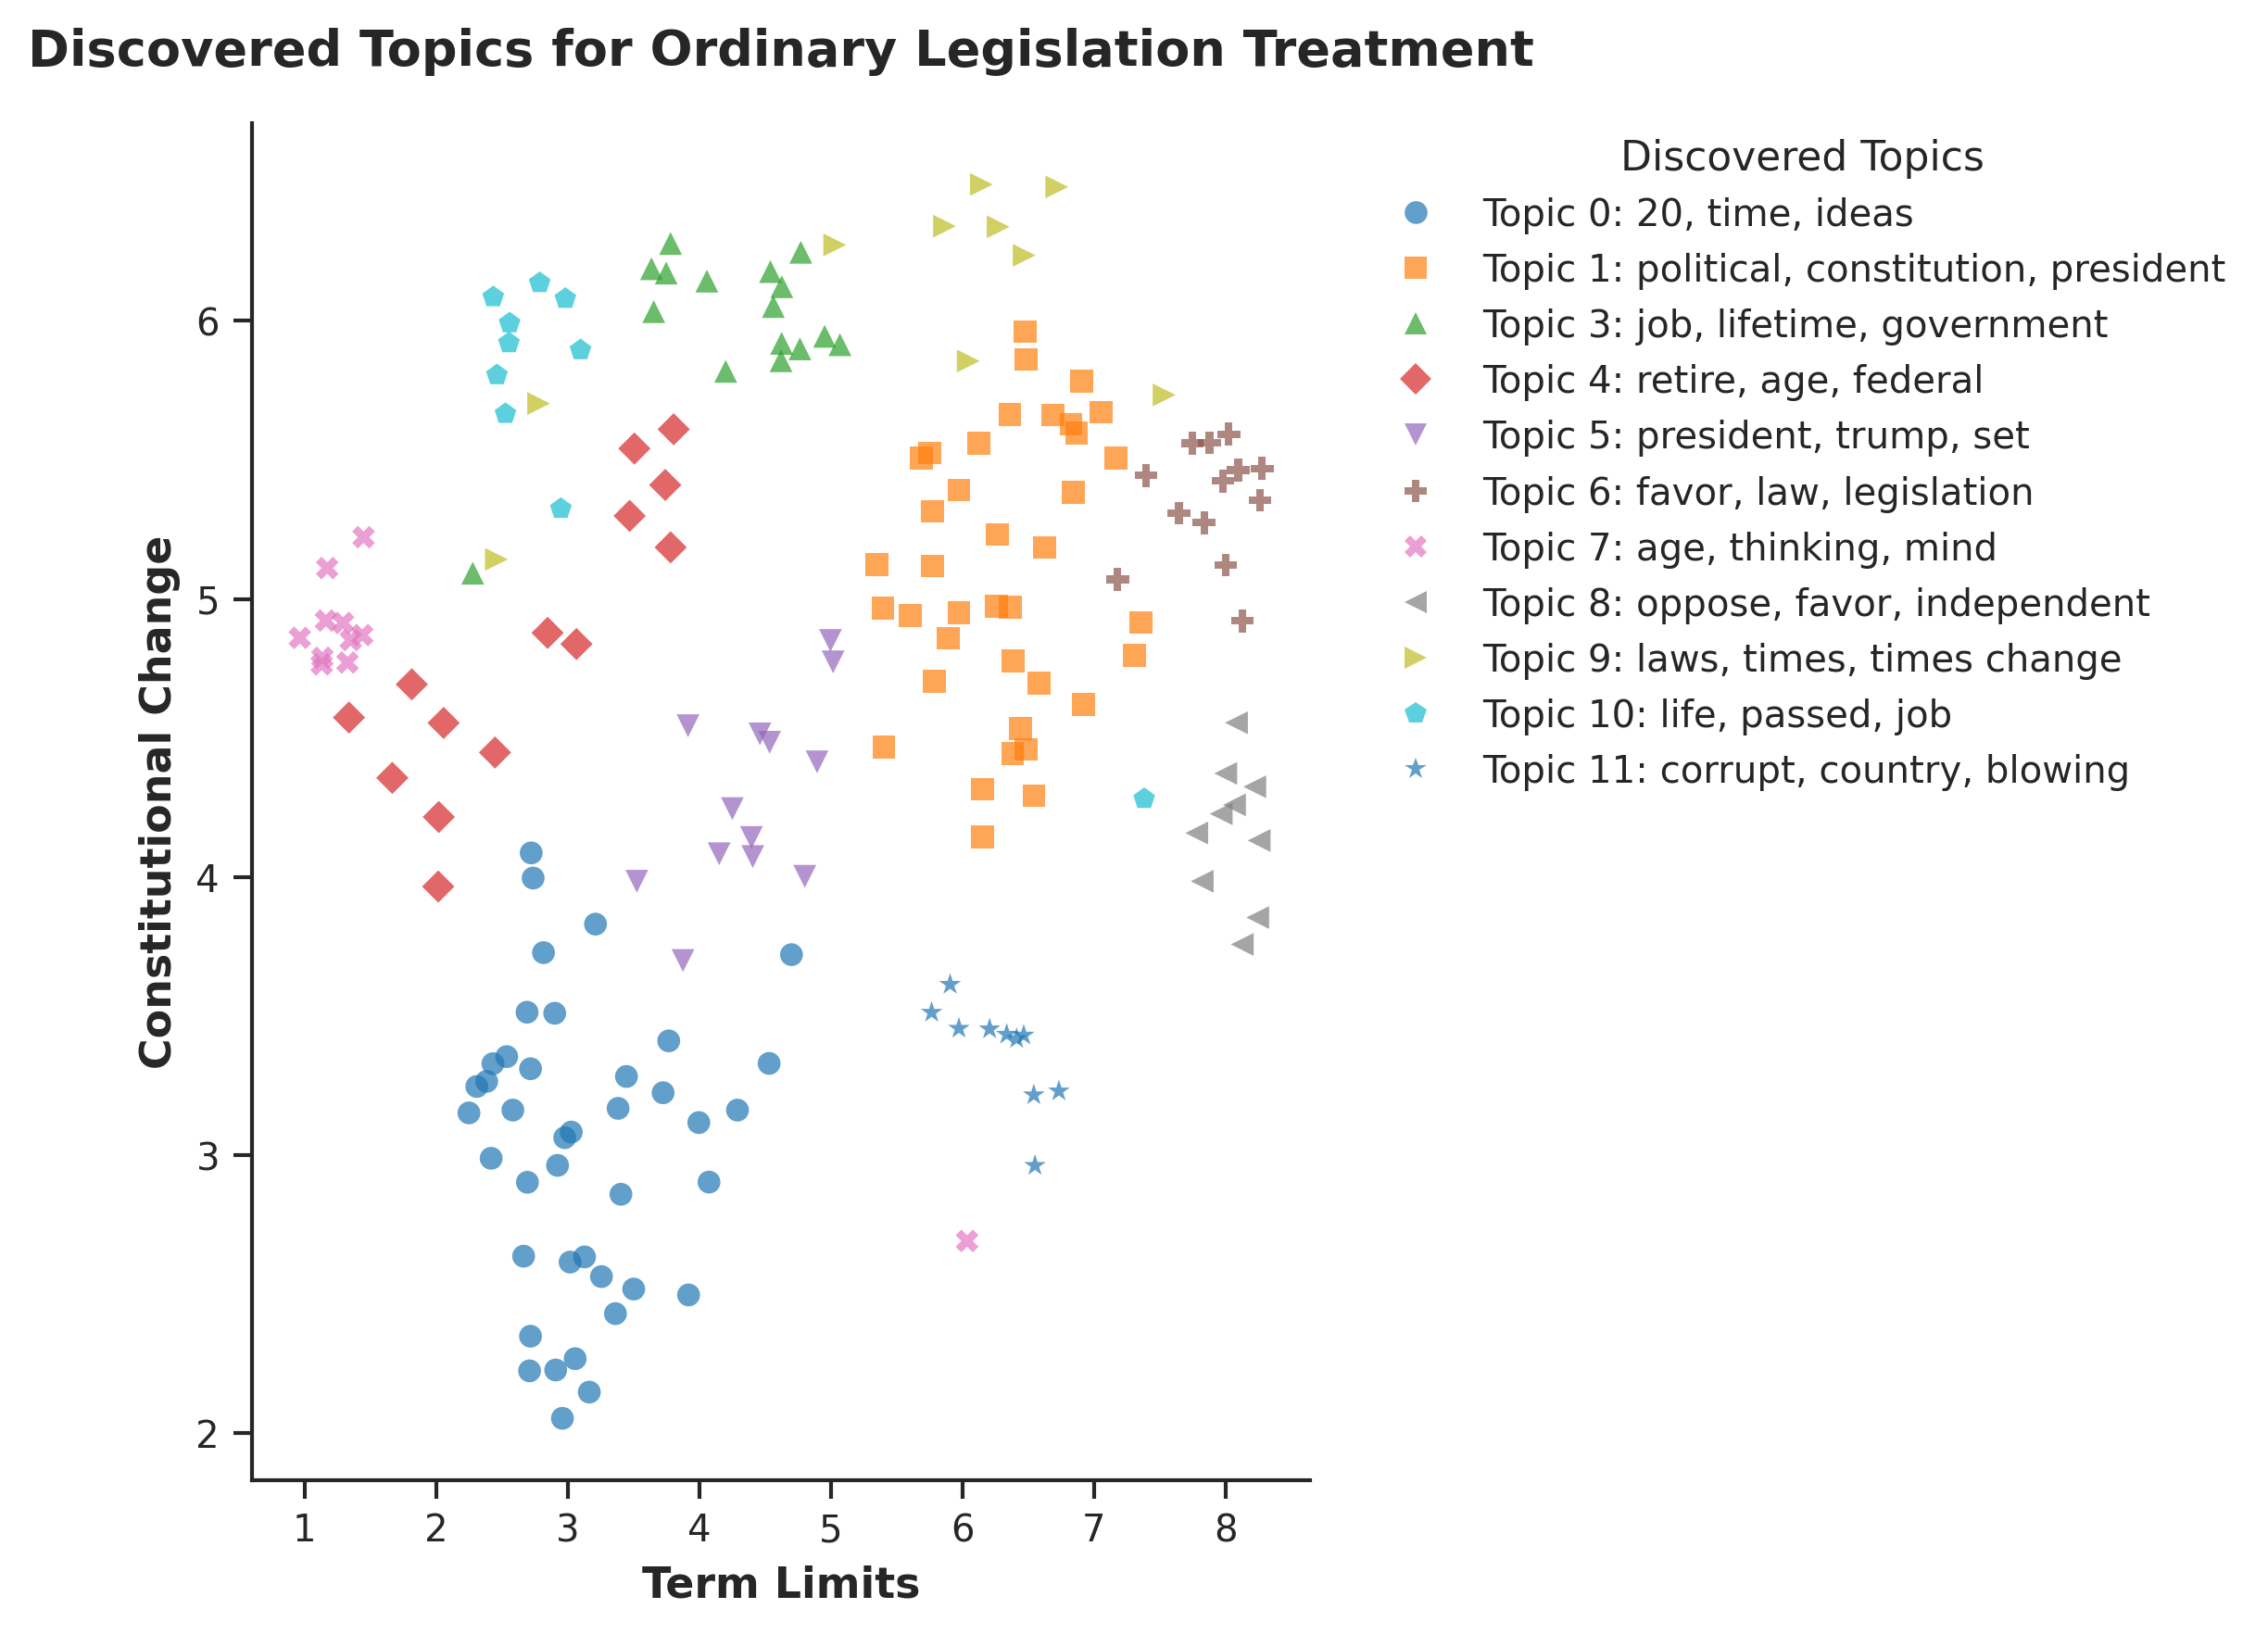

In [10]:
import matplotlib.pyplot as plt
import seaborn as sns
import umap
import numpy as np
import pandas as pd

# --- 1. Create a Topic-to-Name Mapping Table ---
# We extract the clean top keywords from the "Representation" list for the legend labels
def clean_label(row):
    if row['Topic'] == -1:
        return "Outliers"
    # Join top 3 terms with a comma for a concise legend name
    return f"Topic {row['Topic']}: {', '.join(row['Representation'][:3])}"

topic_info['Clean_Label'] = topic_info.apply(clean_label, axis=1)
label_dict = pd.Series(topic_info.Clean_Label.values, index=topic_info.Topic).to_dict()


# --- 2. Filter out Outliers (-1) and Topic 2 from arrays ---
embeddings_arr = np.array(embeddings)
topics_arr = np.array(topics)

# Filter out -1 and topic 2 (you can chain additional topics here if needed, e.g., & (topics_arr != 3))
valid_mask = (topics_arr != -1) & (topics_arr != 2)

filtered_embeddings = embeddings_arr[valid_mask]
filtered_topics = topics_arr[valid_mask]

# Convert the numerical topic assignments into their corresponding text labels
text_labels = np.array([label_dict[t] for t in filtered_topics])

# Convert the numerical topic assignments into their corresponding text labels
text_labels = np.array([label_dict[t] for t in filtered_topics])

# --- 3. Perform UMAP Dimensionality Reduction ---
# 'cosine' metric matches best with text embedding geometries
reducer = umap.UMAP(n_neighbors=15, min_dist=0.1, metric='cosine', random_state=42)
embedding_2d = reducer.fit_transform(filtered_embeddings)

# --- 4. Define Academic Journal Styling Rules ---
plt.rcParams['font.family'] = 'sans-serif'
plt.rcParams['font.sans-serif'] = ['Arial', 'Liberation Sans', 'DejaVu Sans']
sns.set_context("paper", font_scale=1.1)
sns.set_style("ticks")

# --- 5. Generate Figure (300 DPI with Distinct Shapes) ---
fig, ax = plt.subplots(figsize=(8, 6), dpi=300)

# Sort unique topics numerically first, then map to their clean labels
unique_numeric_topics = sorted(list(set(filtered_topics)))
unique_sorted_labels = [label_dict[t] for t in unique_numeric_topics]

n_topics = len(unique_sorted_labels)
available_markers = ['o', 's', '^', 'D', 'v', 'P', 'X', '<', '>', 'p', '*', 'h']
markers_list = available_markers[:n_topics]
palette = sns.color_palette("tab10", n_topics)

scatter = sns.scatterplot(
    x=embedding_2d[:, 0],
    y=embedding_2d[:, 1],
    hue=text_labels,
    style=text_labels,
    markers=markers_list,
    hue_order=unique_sorted_labels,
    style_order=unique_sorted_labels,
    palette=palette,
    alpha=0.7,
    s=35,
    edgecolor='none',
    ax=ax
)

# --- 6. Clean Up Ticks and Layout Borders ---
ax.set_xlabel("Term Limits", fontsize=11, fontweight='bold')
ax.set_ylabel("Constitutional Change", fontsize=11, fontweight='bold')
sns.despine() # Strips top and right border lines

ax.set_title("Discovered Topics for Ordinary Legislation Treatment", fontsize=13, fontweight='bold', pad=15)

# Place the legend to the right so it doesn't overlap text clusters
plt.legend(
    title="Discovered Topics",
    bbox_to_anchor=(1.05, 1),
    loc='upper left',
    borderaxespad=0.,
    frameon=False
)

plt.tight_layout()


# Bar Chart of Generated Topics

In [11]:
top_topic_ids = topic_info.loc[topic_info["Topic"] != -1, "Topic"].head(8).tolist()

topic_model.visualize_barchart(
    topics=top_topic_ids,
    n_words=6,
    custom_labels=True,
    width=280,
    height=280,
    title="<b>Distinctive words for Ordinary Legislation</b>",
)